# Lab 04.1 — CNN 1D **from scratch** với NumPy

**Môn:** Intelligent System Development — Lecture 04: *From Mathematical Convolution to NumPy, PyTorch and TensorFlow*

Notebook này cài đặt **toàn bộ** một mạng CNN 1D chỉ bằng NumPy: convolution, ReLU,
pooling, flatten, dense, các hàm mất mát, **đạo hàm thủ công** và vòng lặp huấn luyện.
Không dùng autograd, không dùng framework.

## Nền tảng toán học

Convolution 1D "valid" cho một kênh vào:

$$z_i = \sum_{j=0}^{m-1} k_j\, x_{i+j} + b, \qquad i = 0..L-m$$

Trường hợp tổng quát nhiều kênh (input $X \in \mathbb{R}^{N \times C_{in} \times L}$,
kernel $W \in \mathbb{R}^{C_{out} \times C_{in} \times K}$):

$$Z_{n,o,i} = \sum_{c=1}^{C_{in}} \sum_{j=0}^{K-1} W_{o,c,j}\, X_{n,c,i+j} + b_o$$

Một lớp CNN đầy đủ = convolution + phi tuyến:

$$H = \mathrm{ReLU}(\mathrm{Conv1D}(X; W, b))$$

và cả mạng vẫn là hợp của các hàm:

$$\hat{y} = f_{\theta_3}\Big(\mathrm{Pool}\big[\mathrm{ReLU}(f_{\theta_2}(\mathrm{ReLU}(f_{\theta_1}(X))))\big]\Big)$$

## Ba bộ dữ liệu

| Bộ dữ liệu | Loại | Cách CNN nhìn dữ liệu | Bài toán | Output |
|---|---|---|---|---|
| `diabetes_prediction_dataset.csv` | tabular | 8 đặc trưng = chuỗi 1D dài 8 | phân lớp nhị phân | sigmoid |
| `vietnam_housing_dataset.csv` | tabular | 19 đặc trưng = chuỗi 1D dài 19 | hồi quy giá | linear |
| `YoutubeCommentsDataSet.csv` | text | 60 token = chuỗi 1D dài 60 | phân lớp 3 lớp | softmax |

> **Lưu ý về mô hình hoá.** Dữ liệu tabular không có tính cục bộ không gian
> như ảnh: cột `Glucose` nằm cạnh `BloodPressure` trong CSV không có nghĩa hai biến
> này "gần nhau". Dùng Conv1D cho tabular ở đây là **thí nghiệm dạy học**, không phải
> tuyên bố rằng CNN là mô hình tối ưu cho dữ liệu bảng. Với text thì ngược lại:
> các token cạnh nhau thực sự tạo thành cụm có nghĩa (`[very, good]`, `[not, good]`).

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
import lab04_data as L4

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True)
print("NumPy:", np.__version__)
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

NumPy: 2.4.2


## 1. Phép convolution 1D thủ công

Bắt đầu từ một ví dụ số nhỏ:

$$x = [2, 1, 3, 4, 2], \quad k = [0.5, -1, 0.5], \quad b = 0$$

$$z_1 = 2(0.5) + 1(-1) + 3(0.5), \quad
  z_2 = 1(0.5) + 3(-1) + 4(0.5), \quad
  z_3 = 3(0.5) + 4(-1) + 2(0.5)$$

> **Đối chiếu bằng tay.** $z_1 = 2(0.5) + 1(-1) + 3(0.5) = 1.5$, $z_2 = -0.5$,
> $z_3 = -1.5$. Cell dưới in ra cả ba giá trị tính tay để so với kết quả của hàm
> `conv1d_naive`.

In [2]:
def conv1d_naive(x, k, b=0.0):
    """Convolution 1D 'valid' viet bang vong lap - ban de HIEU, khong de chay nhanh."""
    m = len(k)
    out_len = len(x) - m + 1
    z = np.zeros(out_len)
    for i in range(out_len):          # kernel truot qua tung vi tri
        s = 0.0
        for j in range(m):            # tong co trong so cuc bo
            s += k[j] * x[i + j]
        z[i] = s + b
    return z


x = np.array([2.0, 1.0, 3.0, 4.0, 2.0])
k = np.array([0.5, -1.0, 0.5])

z = conv1d_naive(x, k)
h = np.maximum(z, 0.0)
print("x       =", x)
print("k       =", k)
print("z       =", z)
print("ReLU(z) =", h)

# Kiem tra tung buoc bang tay
z1 = 2 * 0.5 + 1 * (-1) + 3 * 0.5
z2 = 1 * 0.5 + 3 * (-1) + 4 * 0.5
z3 = 3 * 0.5 + 4 * (-1) + 2 * 0.5
print("\nTinh tay: z1 =", z1, " z2 =", z2, " z3 =", z3)
assert np.allclose(z, [z1, z2, z3])

x       = [2. 1. 3. 4. 2.]
k       = [ 0.5 -1.   0.5]
z       = [ 1.5 -0.5 -1.5]
ReLU(z) = [1.5 0.  0. ]

Tinh tay: z1 = 1.5  z2 = -0.5  z3 = -1.5


### Kích thước output và hai tính chất cốt lõi

$$L_{out} = \frac{L - K + 2P}{S} + 1 \quad\Rightarrow\quad \text{với } P=0, S=1:\ L_{out} = L - K + 1$$

* **Local connectivity** — kernel chỉ nhìn $K$ phần tử lân cận.
* **Weight sharing** — *cùng* một bộ $k$ được dùng lại ở mọi vị trí, nên số tham số
  không phụ thuộc độ dài đầu vào (dense layer thì có).

In [3]:
for Lin, K in [(8, 3), (10, 3), (60, 3), (60, 5)]:
    print(f"L={Lin:3d}, K={K} -> L_out = {Lin - K + 1:3d}"
          f" | Conv1D params (1->16 kenh): {16 * 1 * K + 16:4d}"
          f" | Dense tuong duong: {Lin * 16 + 16:5d}")

L=  8, K=3 -> L_out =   6 | Conv1D params (1->16 kenh):   64 | Dense tuong duong:   144
L= 10, K=3 -> L_out =   8 | Conv1D params (1->16 kenh):   64 | Dense tuong duong:   176
L= 60, K=3 -> L_out =  58 | Conv1D params (1->16 kenh):   64 | Dense tuong duong:   976
L= 60, K=5 -> L_out =  56 | Conv1D params (1->16 kenh):   96 | Dense tuong duong:   976


## 2. Mini-framework: các lớp và đạo hàm thủ công

Mỗi lớp là một object có hai phương thức:

* `forward(X)` — tính đầu ra;
* `backward(dOut)` — nhận $\partial \mathcal{L} / \partial \text{output}$, trả về
  $\partial \mathcal{L} / \partial \text{input}$ và tích luỹ gradient cho tham số.

### Đạo hàm của Conv1D

Với $Z_{n,o,i} = \sum_{c,j} W_{o,c,j} X_{n,c,i+j} + b_o$:

$$\frac{\partial \mathcal{L}}{\partial W_{o,c,j}} = \sum_{n,i} \delta_{n,o,i}\, X_{n,c,i+j},
\qquad
\frac{\partial \mathcal{L}}{\partial b_o} = \sum_{n,i} \delta_{n,o,i},
\qquad
\frac{\partial \mathcal{L}}{\partial X_{n,c,t}} = \sum_{o,j:\, i+j=t} W_{o,c,j}\, \delta_{n,o,i}$$

Để chạy nhanh, ta dùng thủ thuật **im2col**: xếp mọi cửa sổ trượt thành một ma trận
rồi convolution trở thành một phép nhân ma trận.

In [4]:
class Layer:
    """Lop co so: params() tra ve danh sach (ten, gia_tri, gradient)."""
    def forward(self, X, training=True):
        raise NotImplementedError

    def backward(self, dOut):
        raise NotImplementedError

    def params(self):
        return []


class Conv1D(Layer):
    """Conv1D 'valid'. Input (N, C_in, L) -> Output (N, C_out, L-K+1)."""

    def __init__(self, c_in, c_out, k, seed=None):
        rng = np.random.default_rng(seed)
        # He init: phu hop voi ReLU
        scale = np.sqrt(2.0 / (c_in * k))
        self.W = rng.normal(0, scale, size=(c_out, c_in, k))
        self.b = np.zeros(c_out)
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self.k = k

    def _im2col(self, X):
        N, C, Lin = X.shape
        K = self.k
        Lout = Lin - K + 1
        cols = np.empty((N, C, K, Lout), dtype=X.dtype)
        for j in range(K):                       # moi vi tri trong kernel
            cols[:, :, j, :] = X[:, :, j:j + Lout]
        return cols.reshape(N, C * K, Lout)

    def forward(self, X, training=True):
        self.X_shape = X.shape
        self.cols = self._im2col(X)                       # (N, C*K, Lout)
        W2 = self.W.reshape(self.W.shape[0], -1)          # (C_out, C_in*K)
        Z = np.einsum("nml,om->nol", self.cols, W2)
        return Z + self.b[None, :, None]

    def backward(self, dZ):
        N, C, Lin = self.X_shape
        K = self.k
        Lout = Lin - K + 1
        W2 = self.W.reshape(self.W.shape[0], -1)

        self.dW = np.einsum("nol,nml->om", dZ, self.cols).reshape(self.W.shape)
        self.db = dZ.sum(axis=(0, 2))

        dcols = np.einsum("nol,om->nml", dZ, W2).reshape(N, C, K, Lout)
        dX = np.zeros(self.X_shape, dtype=dZ.dtype)
        for j in range(K):                       # "tan" gradient ve dung vi tri input
            dX[:, :, j:j + Lout] += dcols[:, :, j, :]
        return dX

    def params(self):
        return [("W", self.W, self.dW), ("b", self.b, self.db)]


class ReLU(Layer):
    """h = max(0, z);  dh/dz = 1 neu z > 0, nguoc lai 0."""

    def forward(self, X, training=True):
        self.mask = X > 0
        return X * self.mask

    def backward(self, dOut):
        return dOut * self.mask


class MaxPool1D(Layer):
    """Max pooling, pool_size = stride = p. Gradient chi chay ve phan tu lon nhat."""

    def __init__(self, p=2):
        self.p = p

    def forward(self, X, training=True):
        N, C, Lin = X.shape
        p = self.p
        Lcut = (Lin // p) * p
        self.Lin, self.Lcut = Lin, Lcut
        Xc = X[:, :, :Lcut].reshape(N, C, Lcut // p, p)
        self.arg = Xc.argmax(axis=3)
        return Xc.max(axis=3)

    def backward(self, dOut):
        N, C, Lout = dOut.shape
        p = self.p
        dXc = np.zeros((N, C, Lout, p), dtype=dOut.dtype)
        n, c, l = np.indices((N, C, Lout))
        dXc[n, c, l, self.arg] = dOut
        dX = np.zeros((N, C, self.Lin), dtype=dOut.dtype)
        dX[:, :, :self.Lcut] = dXc.reshape(N, C, self.Lcut)
        return dX


class GlobalMaxPool1D(Layer):
    """Lay max tren toan bo truc thoi gian: (N, C, L) -> (N, C).

    Rat tu nhien cho text: 'dac trung nay co xuat hien o dau do trong cau khong?'
    """

    def forward(self, X, training=True):
        self.shape = X.shape
        self.arg = X.argmax(axis=2)
        return X.max(axis=2)

    def backward(self, dOut):
        dX = np.zeros(self.shape, dtype=dOut.dtype)
        n, c = np.indices(self.arg.shape)
        dX[n, c, self.arg] = dOut
        return dX


class Flatten(Layer):
    def forward(self, X, training=True):
        self.shape = X.shape
        return X.reshape(X.shape[0], -1)

    def backward(self, dOut):
        return dOut.reshape(self.shape)


class Dense(Layer):
    """h = XW + b."""

    def __init__(self, d_in, d_out, seed=None):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0, np.sqrt(2.0 / d_in), size=(d_in, d_out))
        self.b = np.zeros(d_out)
        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)

    def forward(self, X, training=True):
        self.X = X
        return X @ self.W + self.b

    def backward(self, dOut):
        self.dW = self.X.T @ dOut
        self.db = dOut.sum(axis=0)
        return dOut @ self.W.T

    def params(self):
        return [("W", self.W, self.dW), ("b", self.b, self.db)]


class Embedding(Layer):
    """Tra bang: (N, L) chi so nguyen -> (N, E, L) de dua vao Conv1D.

    Hang 0 la <pad> va duoc giu bang 0 (khong hoc).
    """

    def __init__(self, vocab_size, dim, seed=None):
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0, 0.05, size=(vocab_size, dim))
        self.W[0] = 0.0
        self.dW = np.zeros_like(self.W)

    def forward(self, idx, training=True):
        self.idx = idx
        return self.W[idx].transpose(0, 2, 1)          # (N, L, E) -> (N, E, L)

    def backward(self, dOut):
        dEmb = dOut.transpose(0, 2, 1)                 # (N, L, E)
        self.dW = np.zeros_like(self.W)
        np.add.at(self.dW, self.idx, dEmb)             # cong don theo chi so token
        self.dW[0] = 0.0
        return None                                    # khong co gradient ve "chi so"

    def params(self):
        return [("W", self.W, self.dW)]


class Dropout(Layer):
    """Inverted dropout - chi bat khi training."""

    def __init__(self, p=0.3, seed=0):
        self.p = p
        self.rng = np.random.default_rng(seed)

    def forward(self, X, training=True):
        if not training or self.p <= 0:
            self.mask = None
            return X
        self.mask = (self.rng.random(X.shape) > self.p) / (1.0 - self.p)
        return X * self.mask

    def backward(self, dOut):
        return dOut if self.mask is None else dOut * self.mask


class Sequential:
    """yhat = f_L( ... f_2(f_1(X)) ) - dung nghia 'hop cua cac ham'."""

    def __init__(self, layers):
        self.layers = layers

    def forward(self, X, training=True):
        for layer in self.layers:
            X = layer.forward(X, training=training)
        return X

    def backward(self, dOut):
        for layer in reversed(self.layers):
            dOut = layer.backward(dOut)
        return dOut

    def params(self):
        out = []
        for i, layer in enumerate(self.layers):
            for name, p, g in layer.params():
                out.append((f"{i}.{type(layer).__name__}.{name}", p, g))
        return out

    def n_params(self):
        return int(sum(p.size for _, p, _ in self.params()))

    def summary(self):
        print(f"{'#':>2}  {'Layer':<16} {'params':>8}")
        for i, layer in enumerate(self.layers):
            n = sum(p.size for _, p, _ in layer.params())
            print(f"{i:>2}  {type(layer).__name__:<16} {n:>8,}")
        print(f"{'':>2}  {'TONG':<16} {self.n_params():>8,}")

### Hàm mất mát và optimizer

| Bài toán | Output | Loss |
|---|---|---|
| Nhị phân (Diabetes) | sigmoid | $\mathcal{L} = -\frac{1}{N}\sum [y\log p + (1-y)\log(1-p)]$ |
| Hồi quy (House Price) | linear | $\mathcal{L} = \frac{1}{N}\sum (\hat{y}-y)^2$ |
| 3 lớp (Comments) | softmax | $\mathcal{L} = -\frac{1}{N}\sum \log p_{y}$ |

Điểm đẹp của hai loss đầu ra "logit": gradient rút gọn thành
$\partial \mathcal{L}/\partial z = (p - y)/N$ — chính là chỗ khiến cài đặt từ số 0
vẫn ngắn gọn.

Optimizer: **Adam**, cập nhật $\theta \leftarrow \theta - \eta \hat{m}/(\sqrt{\hat{v}}+\epsilon)$.

In [5]:
def sigmoid(z):
    """On dinh so: tranh exp(so lon)."""
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


def bce_with_logits(z, y):
    """Loss + gradient theo logit. z, y dang (N,)."""
    z = z.ravel()
    p = sigmoid(z)
    eps = 1e-12
    loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
    dz = ((p - y) / len(y)).reshape(-1, 1)
    return loss, dz, p


def mse_loss(z, y):
    z = z.ravel()
    err = z - y
    loss = float(np.mean(err ** 2))
    dz = (2.0 * err / len(y)).reshape(-1, 1)
    return loss, dz, z


def softmax_ce(z, y):
    """z: (N, K) logit, y: (N,) chi so lop."""
    zc = z - z.max(axis=1, keepdims=True)
    ez = np.exp(zc)
    p = ez / ez.sum(axis=1, keepdims=True)
    n = len(y)
    loss = float(-np.mean(np.log(p[np.arange(n), y] + 1e-12)))
    dz = p.copy()
    dz[np.arange(n), y] -= 1.0
    dz /= n
    return loss, dz, p


class Adam:
    def __init__(self, model, lr=1e-3, b1=0.9, b2=0.999, eps=1e-8):
        self.model, self.lr, self.b1, self.b2, self.eps = model, lr, b1, b2, eps
        self.t = 0
        self.m = {n: np.zeros_like(p) for n, p, _ in model.params()}
        self.v = {n: np.zeros_like(p) for n, p, _ in model.params()}

    def step(self):
        self.t += 1
        for name, p, g in self.model.params():
            self.m[name] = self.b1 * self.m[name] + (1 - self.b1) * g
            self.v[name] = self.b2 * self.v[name] + (1 - self.b2) * (g ** 2)
            mhat = self.m[name] / (1 - self.b1 ** self.t)
            vhat = self.v[name] / (1 - self.b2 ** self.t)
            p -= self.lr * mhat / (np.sqrt(vhat) + self.eps)   # sua tai cho (in-place)

## 3. Kiểm tra gradient (gradient check)

Đây là bước **bắt buộc** khi tự viết backward. So sánh gradient giải tích với
gradient số:

$$\frac{\partial \mathcal{L}}{\partial \theta_i} \approx \frac{\mathcal{L}(\theta_i + \varepsilon) - \mathcal{L}(\theta_i - \varepsilon)}{2\varepsilon}$$

Sai số tương đối cỡ $10^{-8}$ trở xuống nghĩa là backward đã đúng.

In [6]:
def grad_check(model, X, y, loss_fn, n_check=12, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    z = model.forward(X)
    _, dz, _ = loss_fn(z, y)
    model.backward(dz)

    rows = []
    plist = model.params()
    for _ in range(n_check):
        name, p, g = plist[rng.integers(len(plist))]
        i = tuple(rng.integers(s) for s in p.shape)
        g_analytic = float(g[i])
        old = p[i]
        p[i] = old + eps
        lp = loss_fn(model.forward(X), y)[0]
        p[i] = old - eps
        lm = loss_fn(model.forward(X), y)[0]
        p[i] = old
        g_num = (lp - lm) / (2 * eps)
        denom = max(abs(g_analytic) + abs(g_num), 1e-12)
        rows.append((name, g_analytic, g_num, abs(g_analytic - g_num) / denom))
    print(f"{'param':<22}{'analytic':>13}{'numeric':>13}{'rel.err':>12}")
    worst = 0.0
    for name, ga, gn, rel in rows:
        print(f"{name:<22}{ga:>13.3e}{gn:>13.3e}{rel:>12.2e}")
        worst = max(worst, rel)
    print(f"\nSai so tuong doi lon nhat: {worst:.2e}")
    return worst


# Mo hinh nho de kiem tra: Conv -> ReLU -> Conv -> ReLU -> Pool -> Flatten -> Dense
check_model = Sequential([
    Conv1D(1, 4, 3, seed=1), ReLU(),
    Conv1D(4, 4, 3, seed=2), ReLU(),
    MaxPool1D(2), Flatten(), Dense(4 * 2, 1, seed=3),
])
Xc = np.random.default_rng(0).normal(size=(6, 1, 8))
yc = np.array([0, 1, 1, 0, 1, 0], dtype=float)
worst = grad_check(check_model, Xc, yc, bce_with_logits)
assert worst < 1e-5, "Backward co loi!"

param                      analytic      numeric     rel.err
6.Dense.b                -2.903e-01   -2.903e-01    1.31e-11
2.Conv1D.b                2.301e-02    2.301e-02    1.27e-09
0.Conv1D.b                1.470e-01    1.470e-01    4.14e-10
0.Conv1D.W               -2.206e-02   -2.206e-02    7.90e-10
0.Conv1D.b                1.880e-01    1.880e-01    3.27e-11
2.Conv1D.b                1.922e-01    1.922e-01    3.11e-11
2.Conv1D.b                2.301e-02    2.301e-02    1.27e-09
6.Dense.b                -2.903e-01   -2.903e-01    1.31e-11
6.Dense.W                 5.858e-03    5.858e-03    5.44e-09
2.Conv1D.b                2.301e-02    2.301e-02    1.27e-09
6.Dense.b                -2.903e-01   -2.903e-01    1.31e-11
0.Conv1D.b                1.880e-01    1.880e-01    3.27e-11

Sai so tuong doi lon nhat: 5.44e-09


In [7]:
# Kiem tra them cho nhanh softmax + Embedding + GlobalMaxPool (nhanh text)
check_txt = Sequential([
    Embedding(20, 6, seed=4),
    Conv1D(6, 5, 3, seed=5), ReLU(),
    GlobalMaxPool1D(), Dense(5, 3, seed=6),
])
Xi = np.random.default_rng(1).integers(1, 20, size=(5, 9))
yi = np.array([0, 2, 1, 1, 0])
worst_txt = grad_check(check_txt, Xi, yi, softmax_ce, n_check=10, seed=3)
assert worst_txt < 1e-5, "Backward text co loi!"

param                      analytic      numeric     rel.err
4.Dense.b                -6.206e-02   -6.206e-02    7.61e-10
0.Embedding.W             0.000e+00    0.000e+00    0.00e+00
4.Dense.b                 6.424e-02    6.424e-02    5.32e-10
1.Conv1D.b               -1.475e-01   -1.475e-01    6.81e-10
0.Embedding.W            -3.400e-02   -3.400e-02    2.14e-09
4.Dense.W                -2.794e-03   -2.794e-03    8.45e-09
0.Embedding.W             1.924e-01    1.924e-01    1.42e-10
0.Embedding.W            -8.749e-02   -8.749e-02    4.46e-10
1.Conv1D.W                1.607e-02    1.607e-02    5.44e-09
1.Conv1D.b               -6.552e-02   -6.552e-02    1.44e-09

Sai so tuong doi lon nhat: 8.45e-09


## 4. Vòng lặp huấn luyện thủ công

Không có `fit()`, không có `optimizer` sẵn: mỗi epoch ta tự
(1) trộn dữ liệu, (2) chia minibatch, (3) forward, (4) tính loss,
(5) backward, (6) gọi Adam cập nhật tham số.

In [8]:
def train(model, Xtr, ytr, Xva, yva, loss_fn, epochs=30, bs=64, lr=1e-3,
          seed=0, verbose_every=5, label=""):
    opt = Adam(model, lr=lr)
    rng = np.random.default_rng(seed)
    hist = {"epoch": [], "train_loss": [], "val_loss": []}
    t0 = time.time()
    n = len(Xtr)
    for ep in range(1, epochs + 1):
        idx = rng.permutation(n)
        tot, seen = 0.0, 0
        for s in range(0, n, bs):
            bi = idx[s:s + bs]
            Xb, yb = Xtr[bi], ytr[bi]
            z = model.forward(Xb, training=True)
            loss, dz, _ = loss_fn(z, yb)
            model.backward(dz)
            opt.step()
            tot += loss * len(bi)
            seen += len(bi)
        tr_loss = tot / seen
        va_loss = loss_fn(model.forward(Xva, training=False), yva)[0]
        hist["epoch"].append(ep)
        hist["train_loss"].append(tr_loss)
        hist["val_loss"].append(float(va_loss))
        if ep % verbose_every == 0 or ep == 1:
            print(f"[{label}] epoch {ep:3d}/{epochs}  train {tr_loss:.4f}  test {va_loss:.4f}")
    hist["train_seconds"] = time.time() - t0
    print(f"[{label}] xong sau {hist['train_seconds']:.1f}s")
    return hist


def predict_batched(model, X, bs=512):
    outs = [model.forward(X[s:s + bs], training=False) for s in range(0, len(X), bs)]
    return np.concatenate(outs, axis=0)


def plot_history(hists, titles, suptitle):
    fig, axes = plt.subplots(1, len(hists), figsize=(5 * len(hists), 3.6))
    axes = np.atleast_1d(axes)
    for ax, h, t in zip(axes, hists, titles):
        ax.plot(h["epoch"], h["train_loss"], label="train")
        ax.plot(h["epoch"], h["val_loss"], label="test")
        ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title(t)
        ax.grid(alpha=.3); ax.legend()
    fig.suptitle(suptitle)
    fig.tight_layout()
    plt.show()

## 5. Thí nghiệm A — Diabetes (tabular → phân lớp nhị phân)

Kiến trúc: `8 → Conv1D(16) → ReLU → Conv1D(16) → ReLU → MaxPool → Flatten → Dense(1) → sigmoid`

Luồng kích thước: $L: 8 \to 6 \to 4 \to 2$ (pool) $\to$ flatten 32 $\to$ 1.

In [9]:
dia = L4.load_diabetes()
Xtr = dia["X_train"][:, None, :]          # (N, 1, 8): 1 kenh, chuoi dai 8
Xte = dia["X_test"][:, None, :]
ytr, yte = dia["y_train"], dia["y_test"]
print("Train:", Xtr.shape, "Test:", Xte.shape, "| ty le duong:", round(ytr.mean(), 4))
print("Dac trung:", dia["feature_names"])

model_dia = Sequential([
    Conv1D(1, 16, 3, seed=11), ReLU(),
    Conv1D(16, 16, 3, seed=12), ReLU(),
    MaxPool1D(2), Flatten(),
    Dense(16 * 2, 1, seed=13),
])
model_dia.summary()

Train: (16000, 1, 8) Test: (4000, 1, 8) | ty le duong: 0.085
Dac trung: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level']
 #  Layer              params
 0  Conv1D                 64
 1  ReLU                    0
 2  Conv1D                784
 3  ReLU                    0
 4  MaxPool1D               0
 5  Flatten                 0
 6  Dense                  33
    TONG                  881


In [10]:
hist_dia = train(model_dia, Xtr, ytr, Xte, yte, bce_with_logits,
                 epochs=30, bs=64, lr=2e-3, label="diabetes")
p_dia = sigmoid(predict_batched(model_dia, Xte).ravel())
m_dia = L4.binary_metrics(yte, p_dia)
print("\nKet qua Diabetes (NumPy from scratch):")
for k in ("accuracy", "precision", "recall", "f1"):
    print(f"  {k:<10}: {m_dia[k]:.4f}")
print(f"  Confusion: TP={m_dia['tp']} FP={m_dia['fp']} FN={m_dia['fn']} TN={m_dia['tn']}")

[diabetes] epoch   1/30  train 0.2927  test 0.1410


[diabetes] epoch   5/30  train 0.1135  test 0.1063


[diabetes] epoch  10/30  train 0.1077  test 0.1054


[diabetes] epoch  15/30  train 0.1032  test 0.0975


[diabetes] epoch  20/30  train 0.0987  test 0.0950


[diabetes] epoch  25/30  train 0.0936  test 0.0925


[diabetes] epoch  30/30  train 0.0905  test 0.0896
[diabetes] xong sau 36.6s

Ket qua Diabetes (NumPy from scratch):
  accuracy  : 0.9690
  precision : 0.9219
  recall    : 0.6941
  f1        : 0.7919
  Confusion: TP=236 FP=20 FN=104 TN=3640


## 6. Thí nghiệm B — House Price (tabular → hồi quy)

Bài toán hồi quy phải đổi đầu ra và hàm mất mát:
neuron tuyến tính + MSE, tuyệt đối không dùng sigmoid.

Mục tiêu học là `log1p(Price)` đã chuẩn hoá; khi đánh giá ta đổi ngược về **tỷ VNĐ**
để MAE/RMSE có ý nghĩa thực tế.

In [11]:
hou = L4.load_housing()
Htr = hou["X_train"][:, None, :]
Hte = hou["X_test"][:, None, :]
gtr, gte = hou["y_train"], hou["y_test"]
print("Train:", Htr.shape, "Test:", Hte.shape)
print("Dac trung:", hou["feature_names"])

# Luong kich thuoc: L = 19 -> 17 (conv k=3) -> 15 (conv k=3) -> 7 (pool 2) -> flatten 16*7
L_h = hou["n_features"]
flat_h = 16 * (((L_h - 2) - 2) // 2)
print(f"L={L_h} -> flatten {flat_h}")

model_hou = Sequential([
    Conv1D(1, 16, 3, seed=21), ReLU(),
    Conv1D(16, 16, 3, seed=22), ReLU(),
    MaxPool1D(2), Flatten(),
    Dense(flat_h, 32, seed=23), ReLU(),
    Dense(32, 1, seed=24),                 # output TUYEN TINH
])
model_hou.summary()

Train: (24178, 1, 19) Test: (6045, 1, 19)
Dac trung: ['Area', 'Frontage', 'Access Road', 'Floors', 'Bedrooms', 'Bathrooms', 'legal_ok', 'furn_full', 'furn_basic', 'has_direction', 'prov_hồ_chí_minh', 'prov_hà_nội', 'prov_bình_dương', 'prov_đà_nẵng', 'prov_đồng_nai', 'prov_hải_phòng', 'prov_khánh_hòa', 'prov_hưng_yên', 'prov_other']
L=19 -> flatten 112
 #  Layer              params
 0  Conv1D                 64
 1  ReLU                    0
 2  Conv1D                784
 3  ReLU                    0
 4  MaxPool1D               0
 5  Flatten                 0
 6  Dense               3,616
 7  ReLU                    0
 8  Dense                  33
    TONG                4,497


In [12]:
hist_hou = train(model_hou, Htr, gtr, Hte, gte, mse_loss,
                 epochs=40, bs=128, lr=3e-3, label="housing")

pred_scaled = predict_batched(model_hou, Hte).ravel()
pred_bil = L4.housing_to_billion(pred_scaled, hou)
true_bil = L4.housing_to_billion(gte, hou)
m_hou = L4.regression_metrics(true_bil, pred_bil)
m_hou_log = L4.regression_metrics(hou["y_test_log"], pred_scaled * hou["y_sd"] + hou["y_mu"])
print("\nKet qua House Price (NumPy from scratch), don vi ty VND:")
print(f"  MAE  = {m_hou['mae']:.3f} ty")
print(f"  RMSE = {m_hou['rmse']:.3f} ty")
print(f"  R2   = {m_hou['r2']:.4f}")
print(f"  (tren thang log1p: MAE={m_hou_log['mae']:.4f}, R2={m_hou_log['r2']:.4f})")

[housing] epoch   1/40  train 0.8372  test 0.6538


[housing] epoch   5/40  train 0.5375  test 0.5668


[housing] epoch  10/40  train 0.5202  test 0.5489


[housing] epoch  15/40  train 0.5075  test 0.5438


[housing] epoch  20/40  train 0.5013  test 0.5367


[housing] epoch  25/40  train 0.4921  test 0.5476


[housing] epoch  30/40  train 0.4895  test 0.5493


[housing] epoch  35/40  train 0.4830  test 0.5348


[housing] epoch  40/40  train 0.4784  test 0.5370
[housing] xong sau 152.1s



Ket qua House Price (NumPy from scratch), don vi ty VND:
  MAE  = 1.312 ty
  RMSE = 1.675 ty
  R2   = 0.4367
  (tren thang log1p: MAE=0.2038, R2=0.4753)


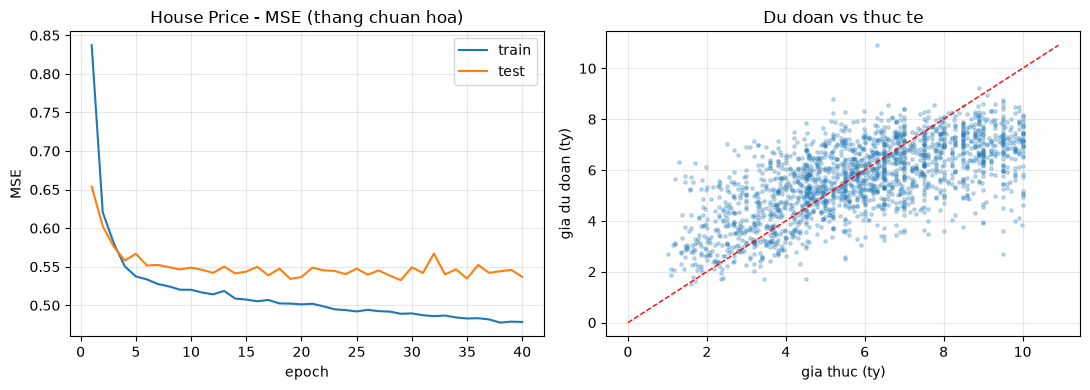

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist_hou["epoch"], hist_hou["train_loss"], label="train")
ax[0].plot(hist_hou["epoch"], hist_hou["val_loss"], label="test")
ax[0].set_title("House Price - MSE (thang chuan hoa)")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("MSE"); ax[0].grid(alpha=.3); ax[0].legend()
sub = np.random.default_rng(0).choice(len(true_bil), size=min(2000, len(true_bil)), replace=False)
ax[1].scatter(true_bil[sub], pred_bil[sub], s=6, alpha=.25)
lims = [0, max(true_bil.max(), pred_bil.max())]
ax[1].plot(lims, lims, "r--", lw=1)
ax[1].set_xlabel("gia thuc (ty)"); ax[1].set_ylabel("gia du doan (ty)")
ax[1].set_title("Du doan vs thuc te"); ax[1].grid(alpha=.3)
fig.tight_layout(); plt.show()

## 7. Thí nghiệm C — Comments (text → phân lớp 3 lớp)

Đây là dữ liệu mà Conv1D **thực sự** phù hợp: các token cạnh nhau tạo thành cụm
ngôn ngữ cục bộ. Kiến trúc:

`tokens → Embedding(32) → Conv1D(64, k=3) → ReLU → MaxPool(2) → Conv1D(64, k=3) → ReLU → GlobalMaxPool → Dense(3) → softmax`

Mỗi filter kích thước 3 có thể học một **trigram** như `[not, very, good]`.

In [14]:
com = L4.load_comments()
Ctr, Cte = com["X_train"], com["X_test"]
ltr, lte = com["y_train"], com["y_test"]
print("Train:", Ctr.shape, "Test:", Cte.shape, "| vocab:", com["vocab_size"])
print("Phan bo lop (train):", {com["class_names"][c]: int((ltr == c).sum()) for c in range(3)})

model_com = Sequential([
    Embedding(com["vocab_size"], 32, seed=31),
    Conv1D(32, 64, 3, seed=32), ReLU(),
    MaxPool1D(2),
    Conv1D(64, 64, 3, seed=33), ReLU(),
    GlobalMaxPool1D(),
    Dropout(0.3, seed=34),
    Dense(64, 3, seed=35),
])
model_com.summary()

Train: (14692, 60) Test: (3672, 60) | vocab: 15000
Phan bo lop (train): {'negative': 1870, 'neutral': 3700, 'positive': 9122}
 #  Layer              params
 0  Embedding         480,000
 1  Conv1D              6,208
 2  ReLU                    0
 3  MaxPool1D               0
 4  Conv1D             12,352
 5  ReLU                    0
 6  GlobalMaxPool1D         0
 7  Dropout                 0
 8  Dense                 195
    TONG              498,755


In [15]:
# 4 epoch: qua epoch 2-3 mo hinh bat dau overfit (xem loss curve o duoi),
# nen ca 3 framework deu dung 4 epoch cho cong bang.
EPOCHS_COM = 4
hist_com = train(model_com, Ctr, ltr, Cte, lte, softmax_ce,
                 epochs=EPOCHS_COM, bs=64, lr=1.5e-3, verbose_every=1, label="comments")

logits = predict_batched(model_com, Cte, bs=256)
ez = np.exp(logits - logits.max(axis=1, keepdims=True))
probs = ez / ez.sum(axis=1, keepdims=True)
m_com = L4.multiclass_metrics(lte, probs)
print("\nKet qua Comments (NumPy from scratch):")
print(f"  accuracy    = {m_com['accuracy']:.4f}")
print(f"  macro F1    = {m_com['macro_f1']:.4f}")
print(f"  weighted F1 = {m_com['weighted_f1']:.4f}")
for c, name in enumerate(com["class_names"]):
    d = m_com["per_class"][c]
    print(f"  {name:<9} P={d['precision']:.3f} R={d['recall']:.3f} F1={d['f1']:.3f} (n={d['support']})")

[comments] epoch   1/4  train 0.7631  test 0.6314


[comments] epoch   2/4  train 0.5137  test 0.5845


[comments] epoch   3/4  train 0.3343  test 0.6574


[comments] epoch   4/4  train 0.1946  test 0.7954
[comments] xong sau 257.7s



Ket qua Comments (NumPy from scratch):
  accuracy    = 0.7467
  macro F1    = 0.6444
  weighted F1 = 0.7405
  negative  P=0.493 R=0.516 F1=0.504 (n=467)
  neutral   P=0.645 R=0.514 F1=0.572 (n=925)
  positive  P=0.828 R=0.889 F1=0.857 (n=2280)


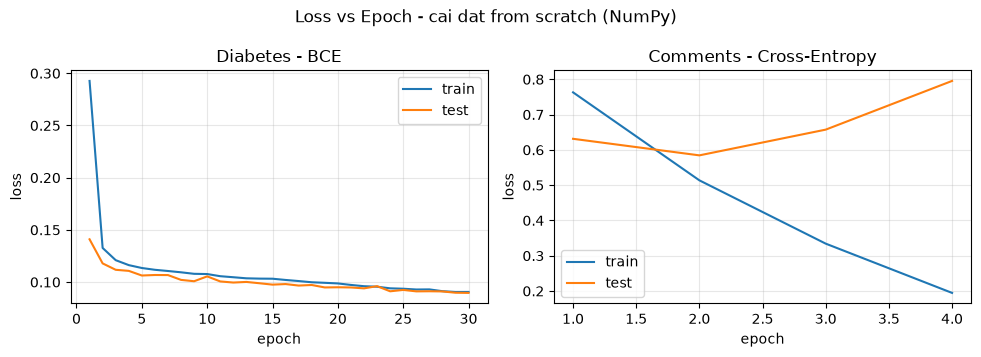

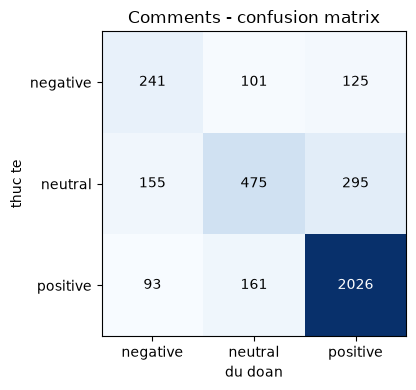

In [16]:
plot_history([hist_dia, hist_com], ["Diabetes - BCE", "Comments - Cross-Entropy"],
             "Loss vs Epoch - cai dat from scratch (NumPy)")

# Confusion matrix cho Comments
cm = np.zeros((3, 3), dtype=int)
for t, p in zip(lte, probs.argmax(axis=1)):
    cm[t, p] += 1
fig, ax = plt.subplots(figsize=(4.4, 4))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3), com["class_names"]); ax.set_yticks(range(3), com["class_names"])
ax.set_xlabel("du doan"); ax.set_ylabel("thuc te"); ax.set_title("Comments - confusion matrix")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.tight_layout(); plt.show()

## 8. Lưu kết quả và nhận xét

Kết quả được ghi ra `results/*.json` để notebook báo cáo (04) tổng hợp và so sánh
ba cách cài đặt.

In [17]:
L4.save_result("numpy", "diabetes", m_dia,
               extra=dict(history=hist_dia, n_params=model_dia.n_params(),
                          seconds=hist_dia["train_seconds"], epochs=30))
L4.save_result("numpy", "housing", dict(**m_hou, mae_log=m_hou_log["mae"], r2_log=m_hou_log["r2"]),
               extra=dict(history=hist_hou, n_params=model_hou.n_params(),
                          seconds=hist_hou["train_seconds"], epochs=40))
L4.save_result("numpy", "comments", m_com,
               extra=dict(history=hist_com, n_params=model_com.n_params(),
                          seconds=hist_com["train_seconds"], epochs=EPOCHS_COM))
print("Da luu results/numpy_*.json")

Da luu results/numpy_*.json


### Nhận xét cho notebook từ số 0

1. **Gradient check là bằng chứng cài đặt đúng.** Sai số tương đối $\sim 10^{-9}$
   cho cả nhánh conv/dense và nhánh embedding/softmax.
2. **Toán học không hề khó hơn dense layer.** Conv1D backward chỉ là ba công thức:
   một tổng cho $dW$, một tổng cho $db$, và một phép "tán" gradient về input.
3. **Chi phí nằm ở kỹ thuật.** Điều khiến bản from-scratch chậm không phải là công
   thức mà là việc thiếu kernel tối ưu: im2col tạo mảng trung gian lớn, mọi thứ chạy
   trên một luồng CPU, và không có fused op. Đây chính là phần PyTorch/TensorFlow
   thay thế — **không phải phần toán**.
4. **Tabular vs text.** Với Diabetes/House Price, CNN chỉ trộn các cột cạnh nhau
   trong CSV (thứ tự cột là ngẫu nhiên về mặt ngữ nghĩa) nên không vượt trội; với
   Comments, convolution bắt được cụm token thật sự có nghĩa.